# Vision — Plat Nomor (deteksi → OCR → koreksi format Indonesia)
**Kapan dipakai:** soal meminta teks plat dari foto kendaraan/CCTV, menghitung kendaraan per
daerah (huruf depan plat), atau mengecek plat yang tidak valid.

**Langkah:**
1. Deteksi: YOLO11 nano khusus plat Indonesia (5,5 MB, `pretrained/plat_yolo11`) → kotak plat.
   Alternatif tanpa model (baris `#`): kontur + morfologi OpenCV klasik.
2. OCR: EasyOCR, hanya huruf besar dan angka, ambil baris teks utama.
3. Koreksi: plat Indonesia = 1–2 huruf + 1–4 angka + 0–3 huruf, mis. `B1234XYZ`.
   Huruf di slot angka diperbaiki (O→0, I→1, B→8, S→5) dan sebaliknya, sesuai posisi.

**Data demo:** potongan plat Indonesia berlabel (IND-number-plate, 150 gambar) untuk mengukur
OCR, dan 6 foto kendaraan dari Wikimedia Commons (CC BY-SA) untuk tahap deteksi.

In [1]:
import glob
import os
import re

import cv2
import easyocr
import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.metrics import accuracy_score
from ultralytics import YOLO

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/plat_nomor"   # GANTI saat lomba
CROPS_CSV = f"{DATA_FOLDER}/potongan.csv"      # potongan plat berlabel
CROP_FOLDER = f"{DATA_FOLDER}/potongan"
SCENE_FOLDER = f"{DATA_FOLDER}/adegan"         # foto kendaraan utuh
SCENE_PATTERN = "*.jpg"
DETECTOR_WEIGHTS = "../../pretrained/plat_yolo11/plate_detector_yolo11n.pt"
EASYOCR_FOLDER = "../../pretrained/easyocr"

CROP_PATH_COL = "path"
PLATE_COL = "plat"
MIN_CONFIDENCE = 0.25   # turunkan (0.1) jika ada plat terlewat, naikkan jika banyak kotak palsu
MARGIN = 0.05           # tambah sedikit tepi di sekeliling kotak sebelum OCR
PLATE_CHARACTERS = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
PLATE_FORMAT = r"[A-Z]{1,2}[0-9]{1,4}[A-Z]{0,3}"
# karakter mirip yang sering tertukar
LETTER_TO_DIGIT = {"O": "0", "I": "1", "B": "8", "S": "5", "Z": "2", "G": "6", "Q": "0", "D": "0"}
DIGIT_TO_LETTER = {"0": "O", "1": "I", "8": "B", "5": "S", "2": "Z", "6": "G"}

## Baca data + muat model

In [3]:
reader = easyocr.Reader(["en", "id"], gpu=torch.cuda.is_available(),
                        model_storage_directory=EASYOCR_FOLDER,
                        user_network_directory=EASYOCR_FOLDER,
                        download_enabled=False, verbose=False)
detector = YOLO(DETECTOR_WEIGHTS)
crops = pd.read_csv(CROPS_CSV)
print(crops.shape)
crops.head()

(150, 2)


,path,plat
0,A1036HZ.jpg,A1036HZ
1,A2526GU.jpg,A2526GU
2,A2826GU.jpg,A2826GU
3,A5758YK.jpg,A5758YK
4,AA62524.jpg,AA62524


## OCR satu plat
EasyOCR bisa memecah plat jadi beberapa potongan (`B`, `1234`, `XYZ`) dan ikut membaca tulisan
kecil (masa berlaku `03·23`). Ambil hanya potongan yang tingginya mirip potongan tertinggi,
lalu urutkan dari kiri.

In [4]:
def read_plate_text(image):
    # gambar (BGR atau path) -> teks plat mentah tanpa spasi
    results = reader.readtext(image, allowlist=PLATE_CHARACTERS)
    if len(results) == 0:
        return ""
    heights = []
    for box, text, score in results:
        heights.append(box[3][1] - box[0][1])        # titik kiri-bawah minus kiri-atas
    pieces = []
    for number in range(len(results)):
        if heights[number] >= 0.6 * max(heights):
            box, text, score = results[number]
            pieces.append((box[0][0], text))          # (posisi x kiri, teks)
    pieces.sort()
    joined = ""
    for left, text in pieces:
        joined = joined + text
    return joined


raw_texts = []
for path in crops[CROP_PATH_COL]:
    raw_texts.append(read_plate_text(f"{CROP_FOLDER}/{path}"))
crops["mentah"] = raw_texts
print("akurasi persis (mentah):", round(accuracy_score(crops[PLATE_COL], crops["mentah"]), 3))

akurasi persis (mentah): 0.74


## Koreksi format plat Indonesia
Coba semua cara memecah teks jadi huruf + angka + huruf. Untuk tiap cara, hitung berapa
karakter yang harus ditukar (mis. `O` di slot angka → `0`). Pilih yang paling sedikit tukar.
Karakter yang tidak bisa diperbaiki diberi biaya 50.

In [5]:
def fit_slot(text, slot):
    # slot = "huruf" atau "angka" -> (teks baru, biaya)
    fixed = ""
    cost = 0
    for character in text:
        if slot == "angka" and character in LETTER_TO_DIGIT:
            fixed = fixed + LETTER_TO_DIGIT[character]
            cost = cost + 1
        elif slot == "huruf" and character in DIGIT_TO_LETTER:
            fixed = fixed + DIGIT_TO_LETTER[character]
            cost = cost + 1
        elif (slot == "angka") != character.isdigit():
            fixed = fixed + character
            cost = cost + 50
        else:
            fixed = fixed + character
    return fixed, cost


print(fit_slot("12O4", "angka"), fit_slot("8Z", "huruf"))

('1204', 1) ('BZ', 1)


In [6]:
def clean_plate(text):
    # pecahan: awalan (1-2 huruf) + angka (1-4) + akhiran (0-3 huruf), koreksi tersedikit
    text = re.sub("[^A-Z0-9]", "", text.upper())
    best_cost = 99
    best_text = text
    for n_prefix in [1, 2]:
        for n_digits in [4, 3, 2, 1]:
            n_suffix = len(text) - n_prefix - n_digits
            if n_suffix < 0 or n_suffix > 3:
                continue
            prefix, cost_a = fit_slot(text[:n_prefix], "huruf")
            digits, cost_b = fit_slot(text[n_prefix:n_prefix + n_digits], "angka")
            suffix, cost_c = fit_slot(text[n_prefix + n_digits:], "huruf")
            if cost_a + cost_b + cost_c < best_cost:
                best_cost = cost_a + cost_b + cost_c
                best_text = prefix + digits + suffix
    return best_text


for example in ["8 1234 ZZ", "AB 12O4 C", "D 8OO DR1", "BG 4S6 ZA0", "B 99"]:
    print(repr(example), "->", clean_plate(example))

'8 1234 ZZ' -> B1234ZZ
'AB 12O4 C' -> AB1204C
'D 8OO DR1' -> D800DRI
'BG 4S6 ZA0' -> BG456ZAO
'B 99' -> B99


## Hasil OCR + koreksi pada potongan berlabel

In [7]:
cleaned = []
valid = []
for text in crops["mentah"]:
    cleaned.append(clean_plate(text))
    valid.append(re.fullmatch(PLATE_FORMAT, cleaned[-1]) is not None)
crops["rapi"] = cleaned
print("akurasi persis mentah:", round(accuracy_score(crops[PLATE_COL], crops["mentah"]), 3))
print("akurasi persis rapi  :", round(accuracy_score(crops[PLATE_COL], crops["rapi"]), 3))
print("format sah setelah koreksi:", round(sum(valid) / len(valid), 3))

wrong = crops[crops[PLATE_COL] != crops["rapi"]]
print(wrong[[PLATE_COL, "mentah", "rapi"]].head(12))
crops.to_csv("ocr_potongan.csv", index=False)

akurasi persis mentah: 0.74
akurasi persis rapi  : 0.82
format sah setelah koreksi: 0.98
        plat   mentah     rapi
4    AA62524  446254S  446254S
5    AA6252S  4A6252S  4A6252S
11   AB2872D  AB2572D  AB2572D
19   AD2253C  AD22530  AD2253O
20   AD2553C  AD25530  AD2553O
32  B1693EVH  B1693EV  B1693EV
47   BA7759Y   BA759Y   BA759Y
62  BM45559Q  BM45590  BM4559O
63   BM6408Q  BM64080  BM6408O
64   BM6448Q  BM64480  BM6448O
65   BM6458Q  BM64580  BM6458O
66   BM6498Q  BM64980  BM6498O


## Deteksi plat di foto kendaraan (YOLO)
Per foto: semua kotak digambar (disimpan `kotak_<nama>`), plat dengan keyakinan tertinggi
dipotong untuk OCR.

In [8]:
scene_paths = sorted(glob.glob(f"{SCENE_FOLDER}/{SCENE_PATTERN}"))
scene_names = []
confidences = []
plate_crops = {}
for scene_path in scene_paths:
    name = os.path.basename(scene_path)
    photo = cv2.imread(scene_path)
    result = detector.predict(photo, conf=MIN_CONFIDENCE, verbose=False)[0]
    boxes = result.boxes.xyxy.cpu().numpy()
    boxes = boxes.astype(int)
    scores = result.boxes.conf.cpu().numpy()
    best_score = 0.0
    if len(scores) > 0:
        best_score = float(scores.max())
        left, top, right, bottom = boxes[scores.argmax()]
        margin_x = int((right - left) * MARGIN)
        margin_y = int((bottom - top) * MARGIN)
        crop = photo[max(top - margin_y, 0):bottom + margin_y,
                     max(left - margin_x, 0):right + margin_x]
        plate_crops[name] = crop.copy()        # salin sebelum kotak hijau digambar
    for left, top, right, bottom in boxes:
        cv2.rectangle(photo, (left, top), (right, bottom), (0, 255, 0), 3)
    cv2.imwrite(f"kotak_{name}", photo)
    scene_names.append(name)
    confidences.append(best_score)
print(pd.Series(confidences, index=scene_names))

byd_sealion_07_ev_at_blok_m_square.jpg                     0.692348
gac_aion_ut_ev_car_at_universitas_widyatama.jpg            0.549066
gwm_tank_300_car_rear_view_at_universitas_widyatama.jpg    0.757168
honda_freed_parked_in_parking_lot.jpg                      0.806413
parked_cars.jpg                                            0.626714
warung_plat_kebumen.jpg                                    0.369696
dtype: float64


## OCR + koreksi untuk potongan hasil deteksi

In [9]:
scene_plates = []
for name in scene_names:
    if name not in plate_crops:
        scene_plates.append("")      # tidak ada plat terdeteksi
        continue
    raw = read_plate_text(plate_crops[name])
    scene_plates.append(clean_plate(raw))
    print(name[:30], "| mentah:", raw, "| rapi:", scene_plates[-1])

byd_sealion_07_ev_at_blok_m_sq | mentah: 9U508 | rapi: 9U508
gac_aion_ut_ev_car_at_universi | mentah: 198UD1 | rapi: I98UDI


gwm_tank_300_car_rear_view_at_ | mentah: SCFAA | rapi: SCFAA


honda_freed_parked_in_parking_ | mentah: BG455HA | rapi: BG455HA
parked_cars.jpg | mentah: LR5091G | rapi: LR5091G


warung_plat_kebumen.jpg | mentah: B1254AJ | rapi: B1254AJ


### Alternatif deteksi tanpa model: kontur + morfologi
Cocok untuk plat besar dan jelas, sering salah di latar ramai. Hapus `#` untuk mencoba di satu
foto.

In [10]:
# photo = cv2.imread(scene_paths[0])
# gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)
# smooth = cv2.bilateralFilter(gray, 11, 17, 17)                # buang noise, pertahankan tepi
# edges = cv2.Canny(smooth, 30, 200)
# kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 5))
# edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)     # sambung huruf jadi satu gumpalan
# contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
# candidates = []
# for contour in contours:
#     left, top, width, height = cv2.boundingRect(contour)
#     if height > 0 and 2.0 < width / height < 6.5 and width > 0.05 * photo.shape[1]:
#         candidates.append((left, top, width, height))     # persegi panjang mirip plat
# print("kotak calon plat:", candidates)

## Submission
Satu baris per foto: teks plat dengan keyakinan deteksi tertinggi.

In [11]:
submission = pd.DataFrame()
submission["gambar"] = scene_names
submission["plat"] = scene_plates
submission.to_csv("submission.csv", index=False)
submission

,gambar,plat
0,byd_sealion_07_ev_at_blok_m_square.jpg,9U508
1,gac_aion_ut_ev_car_at_universitas_widyatama.jpg,I98UDI
2,gwm_tank_300_car_rear_view_at_universitas_widy...,SCFAA
3,honda_freed_parked_in_parking_lot.jpg,BG455HA
4,parked_cars.jpg,LR5091G
5,warung_plat_kebumen.jpg,B1254AJ


## Lihat hasil deteksi

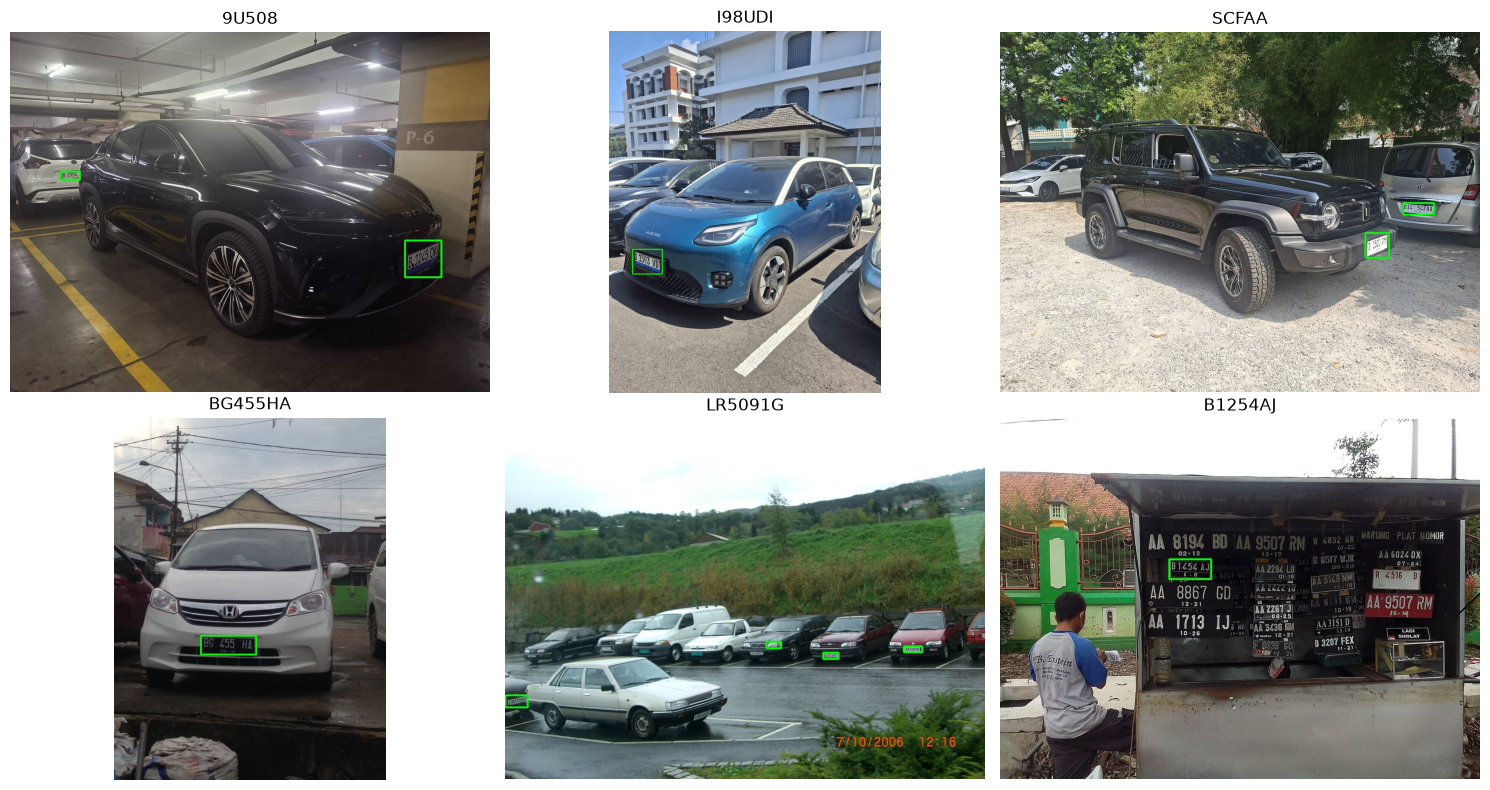

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, name, plate in zip(axes.ravel(), scene_names, scene_plates):
    boxed = cv2.imread(f"kotak_{name}")
    ax.imshow(cv2.cvtColor(boxed, cv2.COLOR_BGR2RGB))
    ax.set_title(plate, fontsize=12)
    ax.axis("off")
plt.tight_layout()
plt.savefig("hasil_deteksi.png", dpi=90)
plt.show()